In [5]:
import pandas as pd

In [6]:
df = pd.read_csv(
    '../dados/chamadosManutencao.csv'
)
df.head()

,idChamado,dataAbertura,unidade,equipamento,tipoManutencao,prioridade,status,tempoAtendimentoHoras,tempoResolucaoHoras,tecnico,categoriaProblema,custo
0,1,2026-03-31,Porto Alegre,Equioamento 026,Preditiva,Crítica,Concluído,7.92,43.71,Técnico 05,Mecânica,2550.33
1,2,2026-08-14,Canoas,Equioamento 003,Preditiva,Alta,Concluído,7.70,36.64,Técnico 05,Mecânica,2536.43
2,3,2026-02-02,Porto Alegre,Equioamento 023,Preventiva,Crítica,Em andamento,10.17,40.10,Técnico 05,Hidráulica,917.32
3,4,2026-04-06,Gravataí,Equioamento 041,Corretiva,Baixa,Em andamento,5.42,50.37,Técnico 02,Eletrônica,2551.30
4,5,2026-02-06,Porto Alegre,Equioamento 060,Preditiva,Baixa,Em andamento,7.23,40.82,Técnico 04,Estrutural,1376.99


In [7]:
df.shape

(500, 12)

In [8]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 12 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   idChamado              500 non-null    int64  
 1   dataAbertura           500 non-null    str    
 2   unidade                500 non-null    str    
 3   equipamento            500 non-null    str    
 4   tipoManutencao         500 non-null    str    
 5   prioridade             500 non-null    str    
 6   status                 500 non-null    str    
 7   tempoAtendimentoHoras  500 non-null    float64
 8   tempoResolucaoHoras    500 non-null    float64
 9   tecnico                500 non-null    str    
 10  categoriaProblema      500 non-null    str    
 11  custo                  500 non-null    float64
dtypes: float64(3), int64(1), str(8)
memory usage: 47.0 KB


In [9]:
df.isnull().sum()

idChamado                0
dataAbertura             0
unidade                  0
equipamento              0
tipoManutencao           0
prioridade               0
status                   0
tempoAtendimentoHoras    0
tempoResolucaoHoras      0
tecnico                  0
categoriaProblema        0
custo                    0
dtype: int64

In [10]:
df.duplicated().sum()

np.int64(0)

In [11]:
df['tipoManutencao'].value_counts()

tipoManutencao
Corretiva     184
Preditiva     170
Preventiva    146
Name: count, dtype: int64

In [12]:
df.describe()

,idChamado,tempoAtendimentoHoras,tempoResolucaoHoras,custo
count,500.000000,500.000000,500.00000,500.000000
mean,250.500000,5.996340,30.24450,1536.302020
std,144.481833,3.383584,14.26526,847.309603
min,1.000000,0.530000,3.20000,105.520000
25%,125.750000,3.000000,17.30500,778.257500
50%,250.500000,5.735000,30.19500,1536.355000
75%,375.250000,8.865000,42.09000,2271.230000
max,500.000000,11.990000,57.43000,2999.960000


In [13]:
df['dataAbertura'] = pd.to_datetime(df['dataAbertura'])
df['dataAbertura'].dtypes

dtype('<M8[us]')

In [14]:
df.dtypes

idChamado                         int64
dataAbertura             datetime64[us]
unidade                             str
equipamento                         str
tipoManutencao                      str
prioridade                          str
status                              str
tempoAtendimentoHoras           float64
tempoResolucaoHoras             float64
tecnico                             str
categoriaProblema                   str
custo                           float64
dtype: object

In [15]:
(df['tempoAtendimentoHoras'] <= 0).sum()
(df['tempoResolucaoHoras'] <= 0).sum()
(df['custo'] <= 0).sum()


np.int64(0)

In [16]:
meses = {
    1: "Janeiro",
    2: "Fevereiro",
    3: "Março",
    4: "Abril",
    5: "Maio",
    6: "Junho",
    7: "Julho",
    8: "Agosto",
    9: "Setembro",
    10: "Outubro",
    11: "Novembro",
    12: "Dezembro"
}

df["mes"] = df["dataAbertura"].dt.month.map(meses)

In [17]:
df["numeroMes"] = df["dataAbertura"].dt.month

In [18]:
df[['dataAbertura', 'mes', 'numeroMes']].head()

,dataAbertura,mes,numeroMes
0,2026-03-31,Março,3
1,2026-08-14,Agosto,8
2,2026-02-02,Fevereiro,2
3,2026-04-06,Abril,4
4,2026-02-06,Fevereiro,2


In [19]:
df.to_csv(
    "../dados/chamadosManutencaoTratados.csv",
    index=False,
    encoding="utf-8-sig"
)

In [19]:
totalChamados = df['idChamado'].nunique()
print(f'Total de chamados {totalChamados}')

chamadosPorStatus = df['status'].value_counts()
chamadosPorStatus

percentualConcluidos = (
    (df["status"] == "Concluído").mean() * 100
)
print(f'Percentual de chamados concluidos: {percentualConcluidos:.2f}%')

custoTotal = df['custo'].sum()
print(f'Custo total R${custoTotal:.2f}')

tempoMedioResolucao = df['tempoResolucaoHoras'].mean()
print(f'Tempo médio de resolução: {tempoMedioResolucao:.2f} horas')

chamadosPorTipo = df['tipoManutencao'].value_counts()
chamadosPorTipo

chamadosPorUnidade = df['unidade'].value_counts()
chamadosPorUnidade

custoPorUnidade = (
    df.groupby("unidade")["custo"]
    .sum()
    .sort_values(ascending=False)
)
custoPorUnidade

tempoPorPrioridade = (
    df.groupby("prioridade")[
        "tempoResolucaoHoras"
    ]
    .mean()
    .sort_values(ascending=False)
)

tempoPorPrioridade

Total de chamados 500
Percentual de chamados concluidos: 32.80%
Custo total R$768151.01
Tempo médio de resolução: 30.24 horas


prioridade
Alta       31.267377
Crítica    31.114046
Baixa      30.793120
Média      27.725820
Name: tempoResolucaoHoras, dtype: float64

In [27]:
chamadosPorStatus.to_csv(
    "../dados/chamadosPorStatus.csv",
    header=["quantidade"]
)

chamadosPorTipo.to_csv(
    "../dados/chamadosPorTipo.csv",
    header=["quantidade"]
)

chamadosPorUnidade.to_csv(
    "../dados/chamadosPorUnidade.csv",
    header=["quantidade"]
)

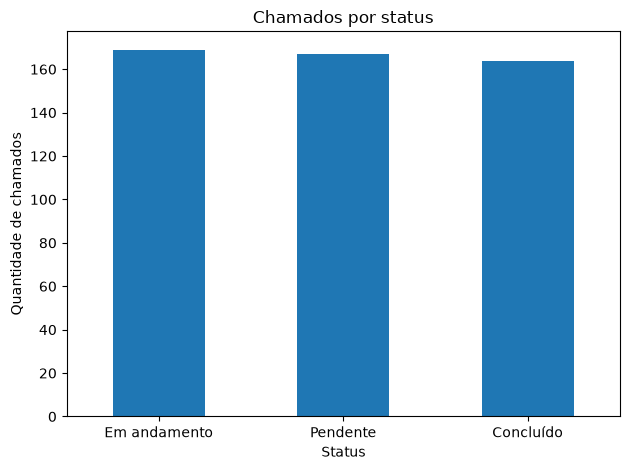

In [20]:

import matplotlib.pyplot as plt

chamadosPorStatus.plot(
    kind="bar",
    title="Chamados por status"
)

plt.xlabel("Status")
plt.ylabel("Quantidade de chamados")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

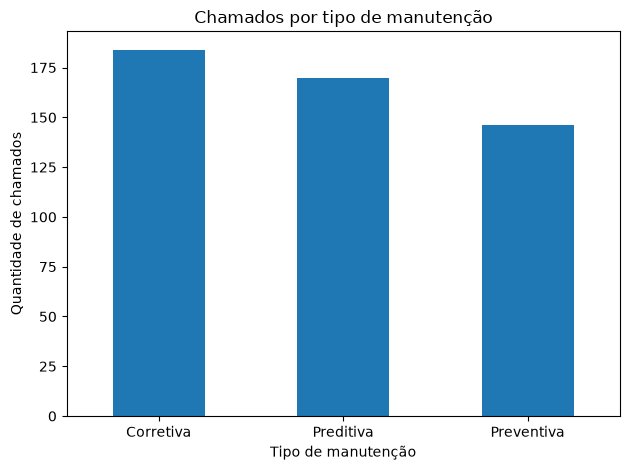

In [21]:
chamadosPorTipo.plot(
    kind="bar",
    title="Chamados por tipo de manutenção"
)

plt.xlabel("Tipo de manutenção")
plt.ylabel("Quantidade de chamados")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

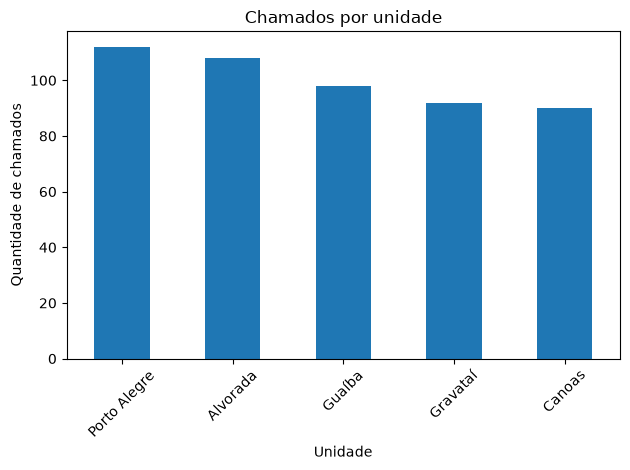

In [22]:
chamadosPorUnidade.plot(
    kind="bar",
    title="Chamados por unidade"
)

plt.xlabel("Unidade")
plt.ylabel("Quantidade de chamados")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

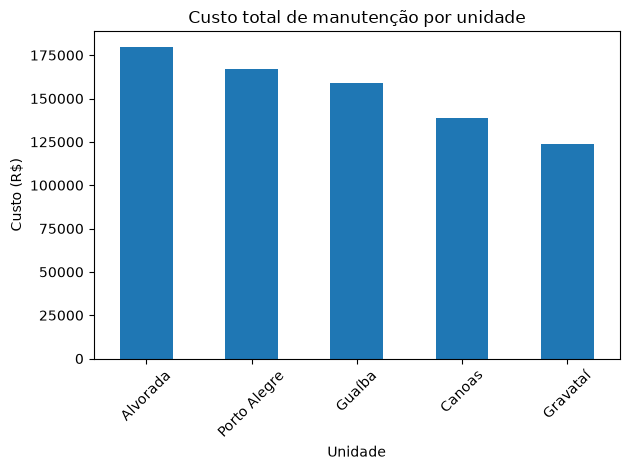

In [23]:
custoPorUnidade.plot(
    kind="bar",
    title="Custo total de manutenção por unidade"
)

plt.xlabel("Unidade")
plt.ylabel("Custo (R$)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

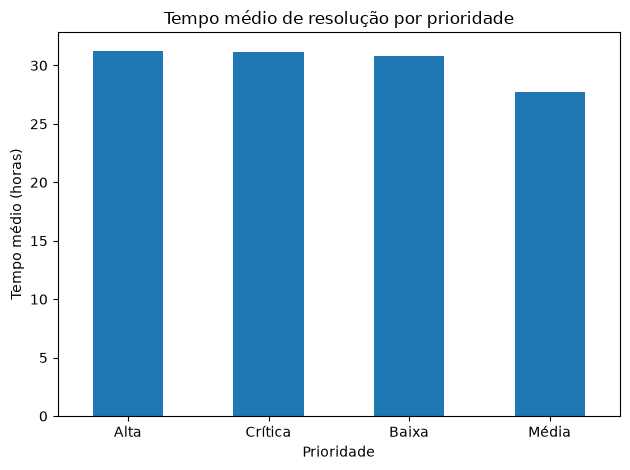

In [24]:
tempoPorPrioridade.plot(
    kind="bar",
    title="Tempo médio de resolução por prioridade"
)

plt.xlabel("Prioridade")
plt.ylabel("Tempo médio (horas)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [27]:
chamadosPorMes = (
    df.groupby(["numeroMes", "mes"])
    .size()
    .sort_index()
)

chamadosPorMes

numeroMes  mes      
1          Janeiro      65
2          Fevereiro    53
3          Março        60
4          Abril        52
5          Maio         60
6          Junho        53
7          Julho        71
8          Agosto       59
9          Setembro     27
dtype: int64

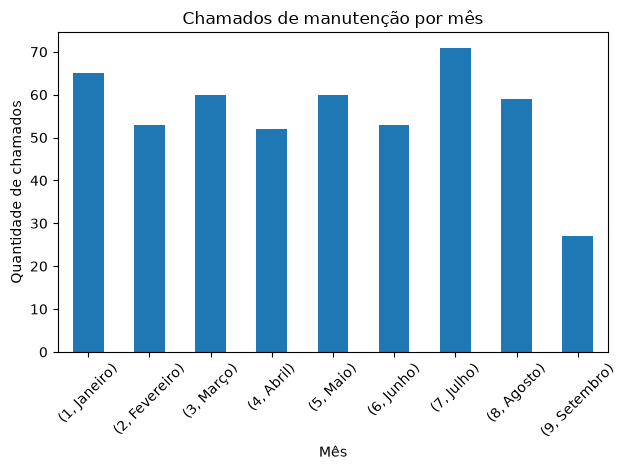

In [28]:
chamadosPorMes.plot(
    kind="bar",
    title="Chamados de manutenção por mês"
)

plt.xlabel("Mês")
plt.ylabel("Quantidade de chamados")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [30]:
custoPorTipo = df.groupby("tipoManutencao")["custo"].sum().sort_values(ascending=False)

custoPorTipo

tipoManutencao
Corretiva     283142.63
Preditiva     257358.72
Preventiva    227649.66
Name: custo, dtype: float64

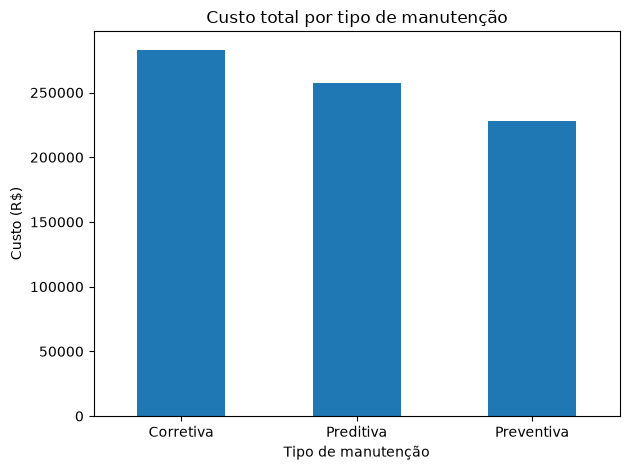

In [31]:
custoPorTipo.plot(
    kind="bar",
    title="Custo total por tipo de manutenção"
)

plt.xlabel("Tipo de manutenção")
plt.ylabel("Custo (R$)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [32]:
comparacaoTipo = pd.DataFrame({
    "Quantidade": chamadosPorTipo,
    "CustoTotal": custoPorTipo
})

comparacaoTipo

,Quantidade,CustoTotal
tipoManutencao,,
Corretiva,184,283142.63
Preditiva,170,257358.72
Preventiva,146,227649.66


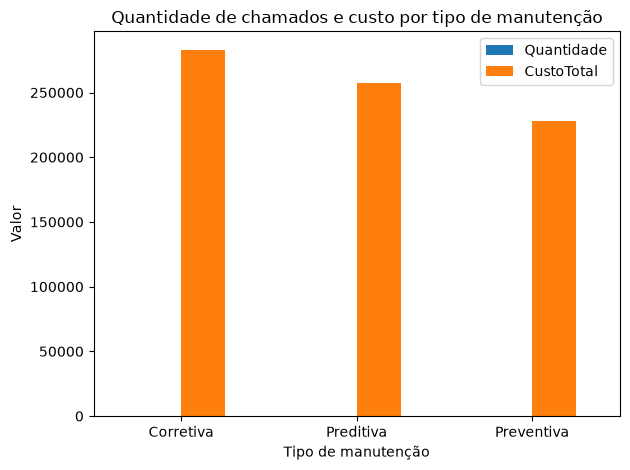

In [33]:
comparacaoTipo.plot(
    kind="bar",
    title="Quantidade de chamados e custo por tipo de manutenção"
)

plt.xlabel("Tipo de manutenção")
plt.ylabel("Valor")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

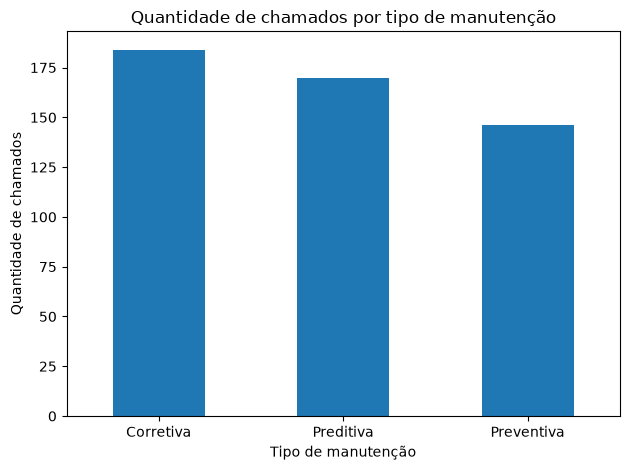

In [34]:
chamadosPorTipo.plot(
    kind="bar",
    title="Quantidade de chamados por tipo de manutenção"
)

plt.xlabel("Tipo de manutenção")
plt.ylabel("Quantidade de chamados")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

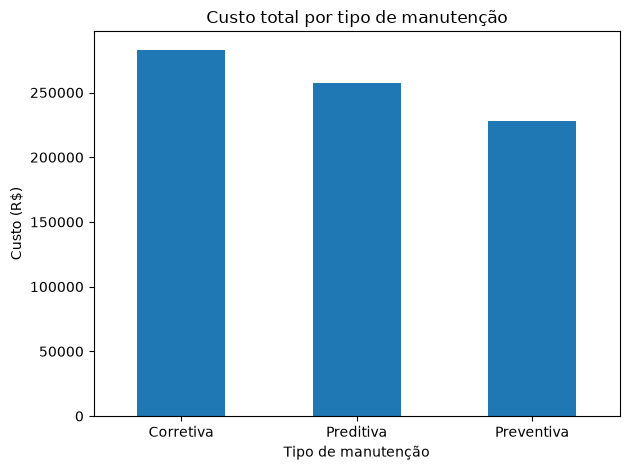

In [35]:
custoPorTipo.plot(
    kind="bar",
    title="Custo total por tipo de manutenção"
)

plt.xlabel("Tipo de manutenção")
plt.ylabel("Custo (R$)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

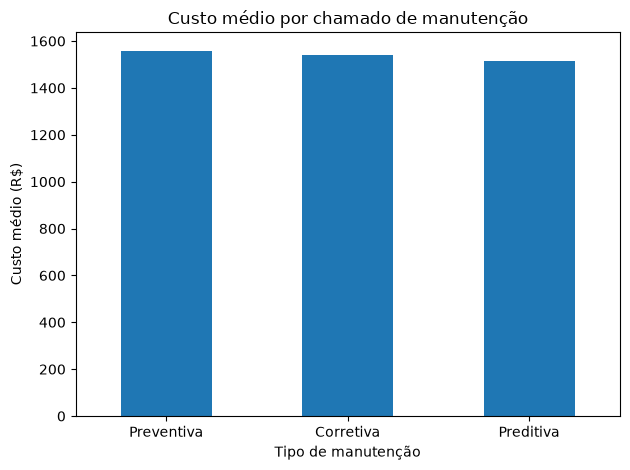

In [37]:
custoMedioPorTipo = df.groupby("tipoManutencao")["custo"].mean().sort_values(ascending=False)

custoMedioPorTipo

custoMedioPorTipo.plot(
    kind="bar",
    title="Custo médio por chamado de manutenção"
)

plt.xlabel("Tipo de manutenção")
plt.ylabel("Custo médio (R$)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [38]:
custoTempo = df[["tempoResolucaoHoras", "custo"]]

custoTempo.head()

,tempoResolucaoHoras,custo
0,43.71,2550.33
1,36.64,2536.43
2,40.10,917.32
3,50.37,2551.30
4,40.82,1376.99


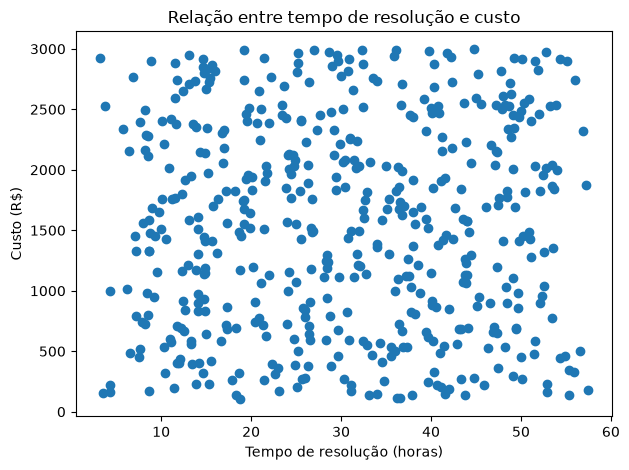

In [39]:
plt.scatter(
    df["tempoResolucaoHoras"],
    df["custo"]
)

plt.title("Relação entre tempo de resolução e custo")
plt.xlabel("Tempo de resolução (horas)")
plt.ylabel("Custo (R$)")
plt.tight_layout()
plt.show()

In [41]:
chamadosPorMes = (
    df.groupby(["numeroMes", "mes"])
    .size()
    .sort_index()
)

chamadosPorMes

numeroMes  mes      
1          Janeiro      65
2          Fevereiro    53
3          Março        60
4          Abril        52
5          Maio         60
6          Junho        53
7          Julho        71
8          Agosto       59
9          Setembro     27
dtype: int64

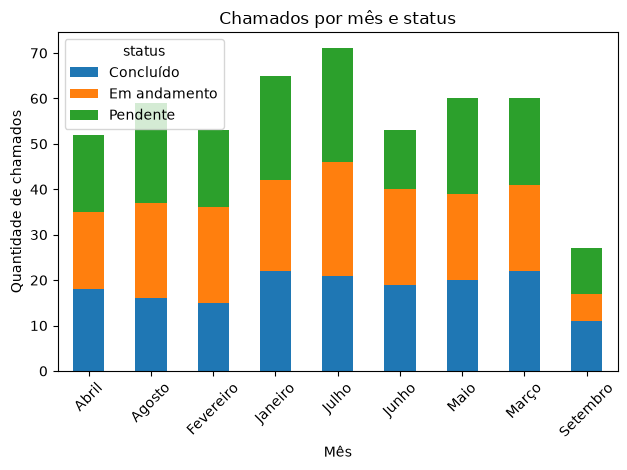

In [42]:
chamadosMesStatus = pd.crosstab(
    df["mes"],
    df["status"]
)

chamadosMesStatus

chamadosMesStatus.plot(
    kind="bar",
    stacked=True,
    title="Chamados por mês e status"
)

plt.xlabel("Mês")
plt.ylabel("Quantidade de chamados")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [43]:
df.to_csv(
    "../dados/baseFinalPowerbi.csv",
    index=False,
    encoding="utf-8-sig"
)